# Seattle : exploration des données (2016)

<h3 style="margin-top:0;">Synopsis</h3>
<p>Vous travaillez pour la <b style="color:#C1121F;">ville de Seattle</b>. Pour atteindre son objectif de <b style="color:#C1121F;">ville neutre en émissions de carbone en 2050</b>, votre équipe s’intéresse de près à la consommation et aux émissions des <b style="color:#C1121F;">bâtiments non destinés à l’habitation</b>.</p>
<p>Des relevés minutieux ont été effectués par les agents de la ville en 2016. Voici les données et leur source. Cependant, ces relevés sont coûteux à obtenir, et à partir de ceux déjà réalisés, vous voulez tenter de prédire les <b style="color:#C1121F;">émissions de CO2</b> et la <b style="color:#C1121F;">consommation totale d’énergie</b> de bâtiments non destinés à l’habitation pour lesquels elles n’ont pas encore été mesurées.</p>
<p>Vous cherchez également à évaluer l’intérêt de l’<b style="color:#1B7F3B;">"ENERGY STAR Score"</b> pour la prédiction d’émissions, qui est fastidieux à calculer avec l’approche utilisée actuellement par votre équipe. Vous l'intégrerez dans la modélisation et jugerez de son intérêt.</p>

**Plan du notebook**

1. Premier aperçu
2. Valeurs manquantes
3. Erreurs et incohérences
4. Fuite de données : les colonnes d'énergie
5. Bilan des décisions

Dans ce notebook, on **explore** : on note les constats et les décisions,
sans nettoyer (sauf le périmètre). Le nettoyage est fait dans
`02_nettoyage.ipynb`, qui applique toutes les décisions d'un coup.

## Imports et chemins

In [64]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Chemins
PROJECT_ROOT = Path.cwd().parent
DATA_RAW = PROJECT_ROOT / "data" / "raw"

# Options d'affichage
pd.set_option("display.max_columns", None)

# 1. Premier aperçu

## 1.1. Chargement et vue d'ensemble

In [65]:
df_raw = pd.read_csv(
    DATA_RAW / "2016-building-energy-benchmarking-6af870b7ba821669818300.csv"
)
df_raw.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [66]:
# Vue d'ensemble de toutes les colonnes
summary = pd.DataFrame({
    "Data Type": df_raw.dtypes,
    "Missing Values": df_raw.isnull().sum(),
    "Percentage Missing": df_raw.isnull().mean() * 100,
    "Unique Values": df_raw.nunique(),
    "Percentage Unique": df_raw.nunique() / len(df_raw) * 100,
    "Mean": df_raw.mean(numeric_only=True),
    "Median": df_raw.median(numeric_only=True),
    "Min": df_raw.min(numeric_only=True),
    "Max": df_raw.max(numeric_only=True),
})

summary.sort_values(by="Missing Values", ascending=False)

,Data Type,Missing Values,Percentage Missing,Unique Values,Percentage Unique,Mean,Median,Min,Max
Comments,float64,3376,100.000000,0,0.000000,NaN,NaN,NaN,NaN
Outlier,str,3344,99.052133,2,0.059242,NaN,NaN,NaN,NaN
YearsENERGYSTARCertified,object,3257,96.475118,65,1.925355,NaN,NaN,NaN,NaN
ThirdLargestPropertyUseTypeGFA,float64,2780,82.345972,501,14.840047,1.173868e+04,5.043000e+03,0.0,459748.0
ThirdLargestPropertyUseType,str,2780,82.345972,44,1.303318,NaN,NaN,NaN,NaN
SecondLargestPropertyUseTypeGFA,float64,1697,50.266588,1352,40.047393,2.844408e+04,1.066400e+04,0.0,686750.0
SecondLargestPropertyUseType,str,1697,50.266588,50,1.481043,NaN,NaN,NaN,NaN
ENERGYSTARScore,float64,843,24.970379,100,2.962085,6.791867e+01,7.500000e+01,1.0,100.0
LargestPropertyUseTypeGFA,float64,20,0.592417,3122,92.476303,7.917764e+04,3.989400e+04,5656.0,9320156.0
LargestPropertyUseType,str,20,0.592417,56,1.658768,NaN,NaN,NaN,NaN


## 1.2. Colonnes inutiles

In [67]:
df_raw["City"].value_counts()

City
Seattle    3376
Name: count, dtype: int64

In [68]:
cols_inutiles = summary.index[summary["Unique Values"] <= 1].tolist()
cols_inutiles

# Ces colonnes ont une seule valeur unique (ou aucune) : elles ne sont donc
# pas informatives pour l'analyse. On les supprimera pendant le nettoyage.

['City', 'Comments', 'DataYear', 'State']

## 1.3. Périmètre : les bâtiments non résidentiels

In [69]:
df_raw["BuildingType"].value_counts()

BuildingType
NonResidential          1460
Multifamily LR (1-4)    1018
Multifamily MR (5-9)     580
Multifamily HR (10+)     110
SPS-District K-12         98
Nonresidential COS        85
Campus                    24
Nonresidential WA          1
Name: count, dtype: int64

In [70]:
# SPS = Seattle Public Schools et K-12 = Kindergarten to 12th grade :
# ces bâtiments sont des établissements scolaires.

# Les bâtiments non résidentiels : la demande se concentre sur ce type.
non_resid = ~df_raw["BuildingType"].str.contains("Multifamily")

# On regarde les types de bâtiments non résidentiels, pour voir lesquels
# sont les plus fréquents et si tout est cohérent.
df_raw.loc[non_resid, "PrimaryPropertyType"].value_counts()

# Certains bâtiments semblent mal classés : 3 « Low-Rise Multifamily »
# (des logements), donc on les exclura aussi.

PrimaryPropertyType
Small- and Mid-Sized Office    292
Other                          250
Warehouse                      187
Large Office                   173
K-12 School                    139
Mixed Use Property             114
Retail Store                    91
Hotel                           76
Worship Facility                71
Distribution Center             53
Supermarket / Grocery Store     40
Medical Office                  39
Self-Storage Facility           28
University                      24
Residence Hall                  21
Senior Care Community           20
Refrigerated Warehouse          12
Restaurant                      12
Hospital                        10
Laboratory                      10
Low-Rise Multifamily             3
Office                           3
Name: count, dtype: int64

In [71]:
resid = (
    df_raw["BuildingType"].str.contains("Multifamily")
    | df_raw["PrimaryPropertyType"].str.contains("Multifamily")
)

df = df_raw.loc[~resid].drop(columns=cols_inutiles)
df.shape

(1665, 42)

# 2. Valeurs manquantes

## 2.1. Vue d'ensemble

In [72]:
manquants = df.isna().mean().mul(100).round(1)
manquants[manquants > 0].sort_values(ascending=False)

Outlier                            99.0
YearsENERGYSTARCertified           94.1
ThirdLargestPropertyUseType        78.9
ThirdLargestPropertyUseTypeGFA     78.9
SecondLargestPropertyUseType       48.8
SecondLargestPropertyUseTypeGFA    48.8
ENERGYSTARScore                    34.4
ZipCode                             1.0
LargestPropertyUseType              0.4
LargestPropertyUseTypeGFA           0.4
SiteEUIWN(kBtu/sf)                  0.2
SiteEnergyUseWN(kBtu)               0.2
SiteEUI(kBtu/sf)                    0.2
ListOfAllPropertyUseTypes           0.1
NumberofBuildings                   0.1
SourceEUIWN(kBtu/sf)                0.1
SourceEUI(kBtu/sf)                  0.1
SiteEnergyUse(kBtu)                 0.1
SteamUse(kBtu)                      0.1
Electricity(kBtu)                   0.1
Electricity(kWh)                    0.1
NaturalGas(therms)                  0.1
NaturalGas(kBtu)                    0.1
TotalGHGEmissions                   0.1
GHGEmissionsIntensity               0.1


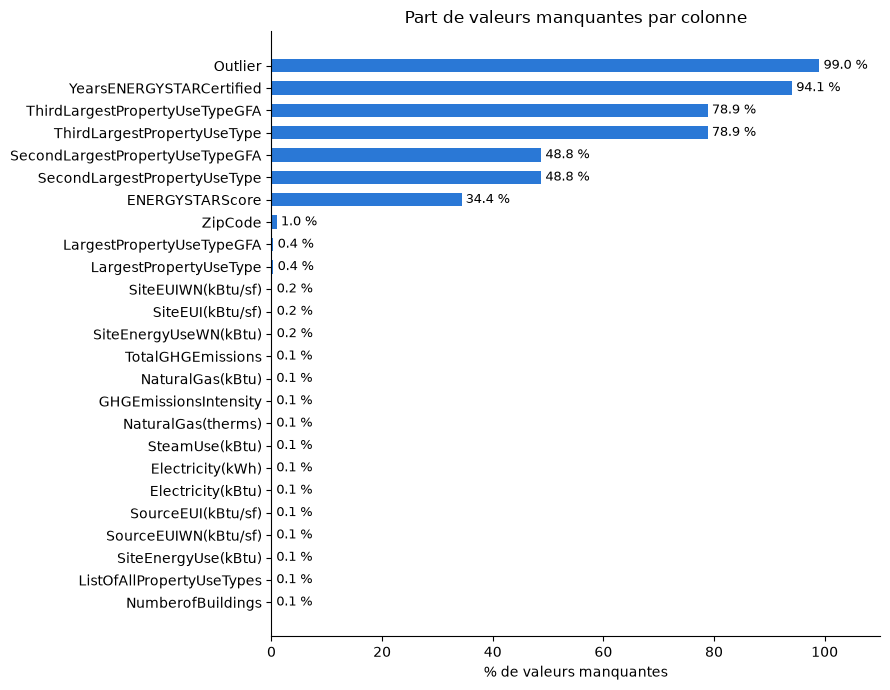

In [73]:
BLEU = "#2a78d6"

pct = df.isna().mean().mul(100)
pct = pct[pct > 0].sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
barres = ax.barh(pct.index, pct.values, color=BLEU, height=0.6)
ax.bar_label(barres, fmt="{:.1f} %", padding=3, fontsize=9)
ax.set_xlim(0, 110)
ax.set_xlabel("% de valeurs manquantes")
ax.set_title("Part de valeurs manquantes par colonne")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

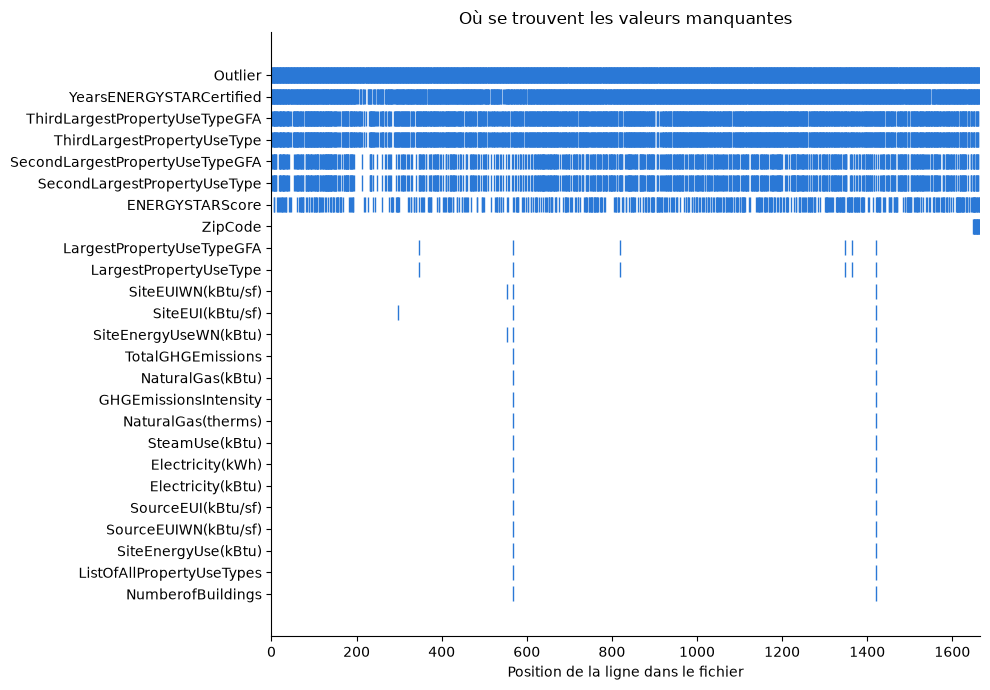

In [74]:
positions = [np.flatnonzero(df[col].isna()) for col in pct.index]

fig, ax = plt.subplots(figsize=(10, 7))
ax.eventplot(positions, colors=BLEU, linelengths=0.7, linewidths=1)
ax.set_yticks(range(len(pct)), pct.index)
ax.set_xlim(0, len(df))
ax.set_xlabel("Position de la ligne dans le fichier")
ax.set_title("Où se trouvent les valeurs manquantes")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Constats sur les graphiques**

- `ZipCode` : un seul petit bloc tout à droite, à regarder de plus près
- 2 traits verticaux qui traversent toutes les colonnes d'énergie
- `ENERGYSTARScore` : des trous répartis partout
- `Second...` et `Third...` : semblent avoir les mêmes valeurs manquantes
  (graphique 1 : même %, graphique 2 : mêmes lignes), à regarder de plus près

## 2.2. ZipCode et coordonnées géographiques

In [75]:
df.loc[df["ZipCode"].isna()]

,OSEBuildingID,BuildingType,PrimaryPropertyType,PropertyName,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
3360,50196,Nonresidential COS,Mixed Use Property,Northgate Community Center,10510 5th Ave NE,NaN,2926049431,5,NORTH,47.70541,-122.32232,2005,1.0,1,20616,0,20616,"Fitness Center/Health Club/Gym, Office, Other ...",Other - Recreation,9900.0,Fitness Center/Health Club/Gym,8577.0,Pre-school/Daycare,1364.0,NaN,NaN,30.900000,30.900000,97.000000,97.000000,6.369655e+05,6.369655e+05,0.0,186683.90630,6.369655e+05,0.000000,0.000000e+00,False,Compliant,NaN,4.44,0.22
3361,50198,Nonresidential COS,Other,Fire Station 06 (New),405 MLK Jr Way S,NaN,1250200565,3,CENTRAL,47.59905,-122.29787,2013,1.0,1,11685,0,11685,Prison/Incarceration,Prison/Incarceration,11685.0,NaN,NaN,NaN,NaN,NaN,NaN,72.800003,82.900002,138.600006,149.199997,8.510538e+05,9.691420e+05,0.0,101784.50000,3.472887e+05,5037.649902,5.037650e+05,False,Compliant,NaN,29.18,2.50
3362,50201,Nonresidential COS,Other,Fire Station 35 (New),8729 15th Ave NW,NaN,3300700810,6,BALLARD,47.69330,-122.37717,2010,1.0,1,11968,0,11968,Prison/Incarceration,Prison/Incarceration,11968.0,NaN,NaN,NaN,NaN,NaN,NaN,65.500000,71.800003,139.199997,149.000000,7.834230e+05,8.587730e+05,0.0,118183.79690,4.032431e+05,3801.799805,3.801800e+05,False,Compliant,NaN,23.00,1.92
3363,50204,Nonresidential COS,Other,Fire Station 39 (New),2806 NE 127th St,NaN,3834500066,5,NORTH,47.72126,-122.29735,1949,1.0,1,11285,0,11285,Prison/Incarceration,Prison/Incarceration,11285.0,NaN,NaN,NaN,NaN,NaN,NaN,57.200001,62.599998,140.000000,148.399994,6.456654e+05,7.059837e+05,0.0,126552.00000,4.317954e+05,2138.700195,2.138700e+05,False,Compliant,NaN,14.37,1.27
3364,50207,Nonresidential COS,Other,Ballard Community Center,6020 28th ave NW,NaN,6658000065,6,BALLARD,47.67295,-122.39228,1911,1.0,1,16795,0,16795,"Fitness Center/Health Club/Gym, Food Service, ...",Other - Recreation,8680.0,Fitness Center/Health Club/Gym,7014.0,Pre-school/Daycare,535.0,NaN,NaN,55.799999,59.000000,126.000000,129.399994,9.366165e+05,9.905455e+05,0.0,158890.50000,5.421344e+05,3944.819824,3.944820e+05,False,Compliant,NaN,24.73,1.47
3365,50208,Nonresidential COS,Other,Ballard Pool,1471 NW 67th St,NaN,3050700005,6,BALLARD,47.67734,-122.37624,1972,1.0,1,12769,0,12769,"Fitness Center/Health Club/Gym, Office, Other ...",Other - Recreation,10912.0,Fitness Center/Health Club/Gym,1670.0,Office,187.0,NaN,NaN,400.799988,420.600006,618.099976,638.900024,5.117308e+06,5.370264e+06,0.0,353216.09380,1.205173e+06,39121.351560,3.912135e+06,False,Compliant,NaN,216.18,16.93
3366,50210,Nonresidential COS,Office,Central West HQ / Brown Bear,1403 w howe,NaN,2425039137,7,MAGNOLIA / QUEEN ANNE,47.63572,-122.37525,1952,1.0,1,13661,0,13661,Office,Office,13661.0,NaN,NaN,NaN,NaN,NaN,75.0,36.799999,40.900002,115.500000,128.399994,5.026677e+05,5.585251e+05,0.0,147323.50000,5.026678e+05,0.000000,0.000000e+00,True,Error - Correct Default Data,NaN,3.50,0.26
3367,50212,Nonresidential COS,Other,Conservatory Campus,1400 E Galer St,NaN,2925049087,3,EAST,47.63228,-122.31574,1912,1.0,1,23445,0,23445,Other - Recreation,Other - Recreation,23445.0,NaN,NaN,NaN,NaN,NaN,NaN,254.899994,286.500000,380.100006,413.200012,5.976246e+06,6.716330e+06,0.0,369539.81250,1.260870e+06,47153.757810,4.715376e+06,False,Compliant,NaN,259.22,11.06
3368,50219,Nonresi

Les valeurs manquantes du `ZipCode` concernent toutes le même type de
bâtiment : « Nonresidential COS ». Cependant, la latitude et la longitude
sont renseignées. On pourrait retrouver le `ZipCode` à partir de ces
coordonnées, ou simplement supprimer la colonne, qui est redondante avec la
latitude et la longitude. Elles sont d'ailleurs bien plus précises qu'un
`ZipCode` : on peut donc se passer de cette information.

In [76]:
# Mais il ne faut jamais faire confiance aux données : la latitude et la
# longitude sont-elles bien renseignées, sans valeurs aberrantes ?
df[["Latitude", "Longitude"]].describe()

# Latitude entre 47,50 et 47,73, longitude entre -122,41 et -122,26 :
# aucune valeur aberrante (pas de 0, pas de point en dehors de la ville).

,Latitude,Longitude
count,1665.000000,1665.000000
mean,47.616040,-122.332911
std,0.048205,0.024599
min,47.499170,-122.411820
25%,47.585420,-122.343280
50%,47.612340,-122.332930
75%,47.649750,-122.321710
max,47.733870,-122.258640


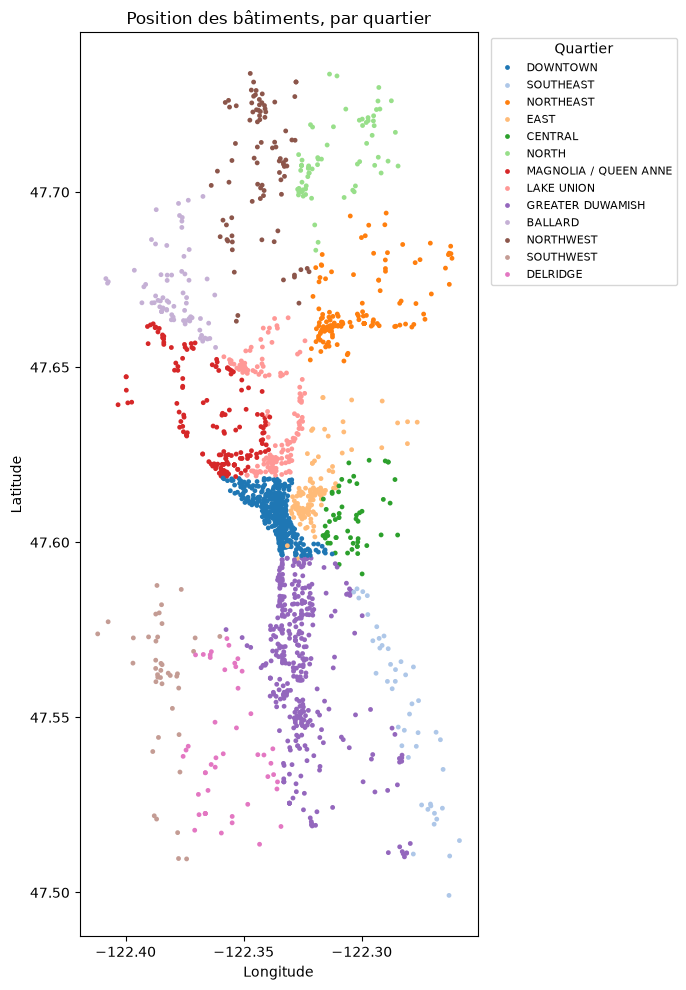

In [77]:
# On vérifie la répartition des bâtiments sur la carte de Seattle, par
# quartier, pour voir s'il y a des incohérences dans les coordonnées.

quartier = (
    df["Neighborhood"].str.upper()
    .replace("DELRIDGE NEIGHBORHOODS", "DELRIDGE")
)

fig, ax = plt.subplots(figsize=(9, 10))
sns.scatterplot(
    data=df, x="Longitude", y="Latitude", hue=quartier,
    palette="tab20", s=12, linewidth=0, ax=ax,
)
ax.set_aspect(1 / np.cos(np.radians(47.6)))
ax.xaxis.set_major_locator(plt.MaxNLocator(4))
ax.ticklabel_format(useOffset=False)
ax.legend(
    title="Quartier", fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left"
)
ax.set_title("Position des bâtiments, par quartier")
plt.tight_layout()
plt.show()

# Cette carte semble cohérente avec Seattle : les bâtiments sont bien
# répartis sur la ville. Par contre, certains quartiers sont moins
# représentés, ce qui pourrait poser problème pour l'analyse.

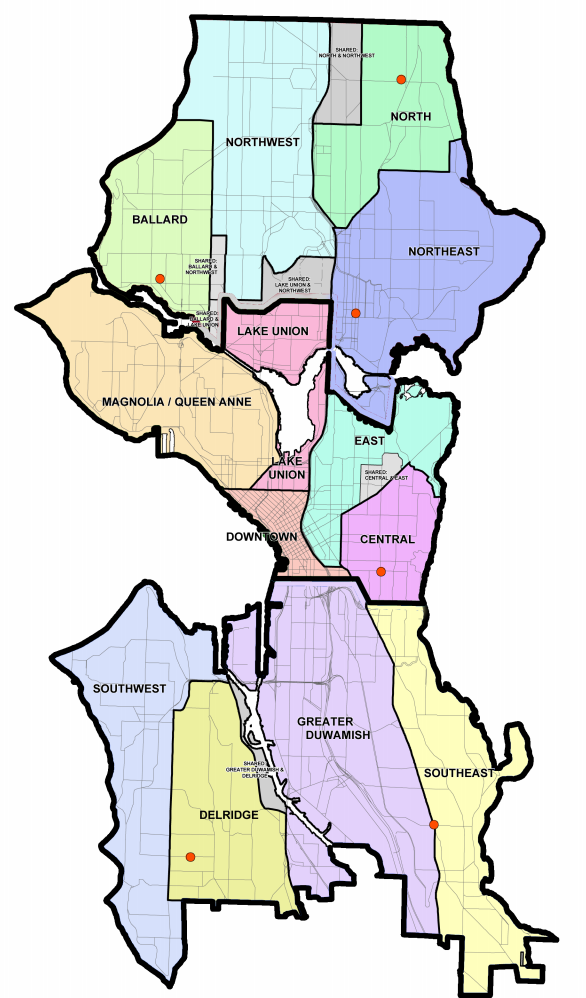

*Carte des quartiers de Seattle (source à préciser), pour comparer avec la
carte des bâtiments : les zones se ressemblent.*

## 2.3. Bâtiments sans relevé d'énergie

In [78]:
cols_releves = [
    "SiteEnergyUse(kBtu)", "TotalGHGEmissions",
    "Electricity(kBtu)", "NaturalGas(kBtu)", "SteamUse(kBtu)",
]
lignes = df[cols_releves].isna().any(axis=1)
df.loc[lignes]

,OSEBuildingID,BuildingType,PrimaryPropertyType,PropertyName,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
578,773,NonResidential,Small- and Mid-Sized Office,SEATTLE BUILDING,215 COLUMBIA ST,98104.0,0939000245,7,DOWNTOWN,47.60380,-122.33293,1924,NaN,4,63150,0,63150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,Non-Compliant,NaN,NaN,NaN
2670,26532,NonResidential,Mixed Use Property,KALBERG BUILDING,4515 UNIVERSITY WAY NE,98105.0,8816401120,4,NORTHEAST,47.66182,-122.31345,1928,NaN,2,20760,0,20760,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,Non-Compliant,NaN,NaN,NaN


Deux bâtiments (un bureau et un bâtiment à usage mixte) n'ont aucune valeur
de consommation ni d'émissions. Ils sont tous les deux « Non-Compliant » :
ils n'ont pas fait leur déclaration. Seules leurs informations de base sont
remplies (adresse, surface, année de construction). Sans cible, ces lignes
ne servent ni à l'entraînement ni à l'évaluation. On ne remplit jamais une
cible, donc on supprimera ces 2 lignes.

## 2.4. Les 2e et 3e usages

In [79]:
# Dans les valeurs manquantes, on voit que les colonnes Second... et
# Third... ont exactement les mêmes valeurs manquantes. On regarde de plus
# près.

cols_usages = [
    "ListOfAllPropertyUseTypes",
    "LargestPropertyUseType",
    "LargestPropertyUseTypeGFA",
    "SecondLargestPropertyUseType",
    "SecondLargestPropertyUseTypeGFA",
    "ThirdLargestPropertyUseType",
    "ThirdLargestPropertyUseTypeGFA",
]
df[cols_usages]

,ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA
0,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN
1,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0
2,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN
3,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN
4,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0
...,...,...,...,...,...,...,...
3371,Office,Office,12294.0,NaN,NaN,NaN,NaN
3372,Other - Recreation,Other - Recreation,16000.0,NaN,NaN,NaN,NaN
3373,"Fitness Center/Health Club/Gym, Other - Recrea...",Other - Recreation,7583.0,Fitness Center/Health Club/Gym,5574.0,Swimming Pool,0.0
3374,"Fitness Center/Health Club/Gym, Food Service, ...",Other - Recreation,6601.0,Fitness Center/Health Club/Gym,6501.0,Pre-school/Daycare,484.0


In [80]:
(
    df["SecondLargestPropertyUseType"].isna()
    == df["SecondLargestPropertyUseTypeGFA"].isna()
).all()

np.True_

In [81]:
(
    df["ThirdLargestPropertyUseType"].isna()
    == df["ThirdLargestPropertyUseTypeGFA"].isna()
).all()

np.True_

In [82]:
# Le 2e usage doit être plus petit que le 1er, et le 3e plus petit que le 2e
cols_gfa = [
    "LargestPropertyUseTypeGFA",
    "SecondLargestPropertyUseTypeGFA",
    "ThirdLargestPropertyUseTypeGFA",
]
print((df[cols_gfa[1]] > df[cols_gfa[0]]).sum())
print((df[cols_gfa[2]] > df[cols_gfa[1]]).sum())

0
0


Quand le 2e (ou le 3e) usage est vide, sa surface est toujours vide aussi.
Il n'y a jamais de 3e usage sans 2e usage, et les surfaces sont bien
classées de la plus grande à la plus petite. Ces vides veulent donc dire
« pas de 2e ou 3e usage », ce ne sont pas des oublis. On les remplira avec
« Aucun » pour le type et 0 pour la surface.

In [83]:
# Certains usages (piscine, parking) ont une surface de 0, ce qui est
# étrange. À investiguer.
for rang in ["Largest", "SecondLargest", "ThirdLargest"]:
    surface_nulle = df[f"{rang}PropertyUseTypeGFA"] == 0
    print(df.loc[surface_nulle, f"{rang}PropertyUseType"].value_counts())

Series([], Name: count, dtype: int64)
SecondLargestPropertyUseType
Parking          74
Swimming Pool     4
Other             1
Retail Store      1
Name: count, dtype: int64
ThirdLargestPropertyUseType
Parking          13
Swimming Pool    10
Retail Store      1
Name: count, dtype: int64


In [84]:
un_seul_usage = df["ListOfAllPropertyUseTypes"] == df["LargestPropertyUseType"]

pd.crosstab(
    df["SecondLargestPropertyUseType"].isna(),
    un_seul_usage,
    rownames=["2e usage vide"],
    colnames=["Un seul usage"],
)

Un seul usage,False,True
2e usage vide,,
False,849,4
True,6,806


In [85]:
exceptions = df["SecondLargestPropertyUseType"].isna() != un_seul_usage
df.loc[exceptions, cols_usages]

,ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA
53,Hotel,Hotel,107547.0,Restaurant,3000.0,NaN,NaN
54,Hotel,Hotel,88490.0,Parking,28300.0,NaN,NaN
353,"Fitness Center/Health Club/Gym, Office, Other ...",NaN,NaN,NaN,NaN,NaN,NaN
384,Retail Store,Retail Store,69800.0,Other,0.0,NaN,NaN
578,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1147,Hotel,NaN,NaN,NaN,NaN,NaN,NaN
2414,Office,NaN,NaN,NaN,NaN,NaN,NaN
2459,Restaurant,NaN,NaN,NaN,NaN,NaN,NaN
2670,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3132,Office,Office,31845.0,Office,31845.0,NaN,NaN


Pour vérifier que le 2e usage est vide quand le bâtiment n'a qu'un seul
usage, on compare la liste complète des usages à l'usage principal : s'ils
sont identiques, le bâtiment n'a qu'un usage. Le tableau croisé montre que
presque tous les bâtiments sont cohérents. Il reste une dizaine
d'exceptions : 6 viennent d'un usage principal vide, et 4 sont de petites
erreurs de saisie (un usage absent de la liste, ou le même usage en 1er et
en 2e). L'hypothèse est confirmée : on pourra remplir les vides avec
« Aucun » et 0.

## 2.5. L'usage principal

In [86]:
cols = ["PropertyName", "ListOfAllPropertyUseTypes", "LargestPropertyUseType"]
df.loc[df["LargestPropertyUseType"].isna(), cols]

,PropertyName,ListOfAllPropertyUseTypes,LargestPropertyUseType
353,Market St Center,"Fitness Center/Health Club/Gym, Office, Other ...",NaN
578,SEATTLE BUILDING,NaN,NaN
1147,Palladian Hotel,Hotel,NaN
2414,Talon Northlake LLC,Office,NaN
2459,BUSH GARDEN - RESTURANT & LOUNGE,Restaurant,NaN
2670,KALBERG BUILDING,NaN,NaN


L'usage principal manque pour 4 bâtiments (en plus des 2 bâtiments sans
relevé). Pour 3 d'entre eux, la liste des usages n'en contient qu'un seul :
on peut donc le recopier, et prendre la surface du bâtiment comme surface de
cet usage (c'est une approximation). Le 4e bâtiment a une dizaine d'usages,
on ne peut pas deviner le principal : on le laisse vide pour l'instant, et
on décidera au moment de choisir les variables du modèle.

## 2.6. ENERGY STAR Score

In [87]:
# ENERGYSTARScore : une colonne qu'on doit étudier, mais où un tiers des
# valeurs sont manquantes.
# Si le manque est au hasard, on doit trouver environ un tiers de vides dans
# tous les groupes de bâtiments. Si le manque dépend d'une variable, certains
# groupes auront beaucoup de vides, d'autres presque pas.

score_par_batiment = (
    df["ENERGYSTARScore"].isna()
    .groupby(df["PrimaryPropertyType"])
    .mean()
    .sort_values()
)
score_par_batiment

PrimaryPropertyType
Hospital                       0.000000
Office                         0.000000
Supermarket / Grocery Store    0.025000
Hotel                          0.039474
Medical Office                 0.051282
Large Office                   0.057803
Worship Facility               0.084507
Residence Hall                 0.095238
Senior Care Community          0.100000
K-12 School                    0.100719
Retail Store                   0.142857
Small- and Mid-Sized Office    0.184932
Warehouse                      0.235294
Distribution Center            0.245283
Refrigerated Warehouse         0.583333
Mixed Use Property             0.771930
Other                          0.956000
Self-Storage Facility          1.000000
Laboratory                     1.000000
Restaurant                     1.000000
University                     1.000000
Name: ENERGYSTARScore, dtype: float64

La part de bâtiments sans score change beaucoup selon le type : presque 0
pour les hôpitaux, les bureaux, les supermarchés..., et 1 pour les
restaurants ou les universités. Le manque ne vient donc pas du hasard. Il
s'explique par le fait que le score ENERGY STAR n'existe que pour certains
types de bâtiments.

> **ATTENTION**
>
> On ne cherche pas à prédire ce score. Nos deux cibles restent la
> consommation d'énergie (`SiteEnergyUse(kBtu)`) et les émissions de CO2
> (`TotalGHGEmissions`).
>
> Le score est une variable d'entrée possible. Il est long à calculer pour
> la ville, donc on veut savoir s'il améliore vraiment les prédictions. Pour
> cela, on comparera deux modèles : un sans le score et un avec, sur les
> bâtiments qui en ont un.
>
> Il faut garder en tête **ses limites** : il n'existe que pour certains
> types de bâtiments, et il est calculé à partir de la **consommation
> mesurée**. Pour un bâtiment qui n'a jamais été mesuré, on ne l'aurait donc
> pas.

## 2.7. YearsENERGYSTARCertified

In [88]:
na_YESC = ~df["YearsENERGYSTARCertified"].isna()
df.loc[na_YESC, "YearsENERGYSTARCertified"].value_counts().sort_index()

YearsENERGYSTARCertified
2007                                                            1
2009                                                            4
2010                                                            2
2011                                                            1
2012                                                            1
                                                               ..
201620152014201320112010200920072000                            1
201720162014201320122011201020092007                            1
2017201620152014201320122011201020092008                        1
2016201520142013201220112010200920082007200620052004            1
201620152014201320122011201020092008200720062005200320022000    1
Name: count, Length: 64, dtype: int64

La colonne `YearsENERGYSTARCertified` est presque vide : un vide veut dire
que le bâtiment n'a jamais été certifié. Les valeurs remplies sont mal
formatées, avec les années collées les unes aux autres (par exemple
`20162015201320122010`). En plus, la certification dépend du score
ENERGY STAR : elle n'apporte pas d'information sur le bâtiment lui-même. On
supprimera donc cette colonne.

## 2.8. Outlier

In [89]:
# Outlier : indique si la propriété est une valeur aberrante haute ou basse
df["Outlier"].value_counts(dropna=False)

# La colonne Outlier est presque vide, mais ce n'est pas un vrai manque :
# un vide veut dire que le bâtiment n'est pas signalé comme anormal.

Outlier
NaN             1649
Low outlier       14
High outlier       2
Name: count, dtype: int64

# 3. Erreurs et incohérences

## 3.1. Les variables catégorielles

In [90]:
# On fait d'abord une vue d'ensemble des variables catégorielles.
# Pour repérer les valeurs écrites de plusieurs façons, on compare le nombre
# de valeurs avant et après passage en majuscules.

cols_cat = df.select_dtypes(exclude=["number", "bool"]).columns

vue_cat = pd.DataFrame({
    "nb_valeurs": df[cols_cat].nunique(),
    "nb_valeurs_normalisees": df[cols_cat].apply(
        lambda col: col.dropna().astype(str).str.upper().str.strip().nunique()
    ),
    "pct_manquants": df[cols_cat].isna().mean().mul(100).round(1),
    "valeur_la_plus_frequente": df[cols_cat].mode().iloc[0],
})
vue_cat["doublons_casse"] = (
    vue_cat["nb_valeurs"] - vue_cat["nb_valeurs_normalisees"]
)
vue_cat.sort_values("nb_valeurs")

,nb_valeurs,nb_valeurs_normalisees,pct_manquants,valeur_la_plus_frequente,doublons_casse
Outlier,2,2,99.0,Low outlier,0
ComplianceStatus,4,4,0.0,Compliant,0
BuildingType,5,5,0.0,NonResidential,0
Neighborhood,19,14,0.0,DOWNTOWN,5
PrimaryPropertyType,21,21,0.0,Small- and Mid-Sized Office,0
ThirdLargestPropertyUseType,39,39,78.9,Office,0
SecondLargestPropertyUseType,47,47,48.8,Parking,0
LargestPropertyUseType,56,56,0.4,Office,0
YearsENERGYSTARCertified,64,64,94.1,2016,0
ListOfAllPropertyUseTypes,370,370,0.1,Office,0


In [91]:
for col in vue_cat.index[vue_cat["nb_valeurs"] <= 25]:
    print(df[col].value_counts().sort_index(), "\n")

BuildingType
Campus                  23
NonResidential        1458
Nonresidential COS      85
Nonresidential WA        1
SPS-District K-12       98
Name: count, dtype: int64 

PrimaryPropertyType
Distribution Center             53
Hospital                        10
Hotel                           76
K-12 School                    139
Laboratory                      10
Large Office                   173
Medical Office                  39
Mixed Use Property             114
Office                           3
Other                          250
Refrigerated Warehouse          12
Residence Hall                  21
Restaurant                      12
Retail Store                    91
Self-Storage Facility           28
Senior Care Community           20
Small- and Mid-Sized Office    292
Supermarket / Grocery Store     40
University                      24
Warehouse                      187
Worship Facility                71
Name: count, dtype: int64 

Neighborhood
BALLARD                    6

Seule la colonne `Neighborhood` a ce problème (par exemple `BALLARD` et
`Ballard`, ou `DELRIDGE NEIGHBORHOODS` pour `DELRIDGE`). On mettra tout en
majuscules et on corrigera Delridge, pour avoir 13 quartiers.

Le tableau montre aussi que `PropertyName`, `Address` et
`TaxParcelIdentificationNumber` sont des identifiants (presque une valeur
différente par bâtiment) : ils ne serviront pas au modèle.

## 3.2. Les variables numériques

In [92]:
cols_num = df.select_dtypes(include="number").columns

vue_num = pd.DataFrame({
    "min": df[cols_num].min(),
    "mediane": df[cols_num].median(),
    "max": df[cols_num].max(),
    "nb_zeros": (df[cols_num] == 0).sum(),
    "nb_negatifs": (df[cols_num] < 0).sum(),
})
vue_num["max_sur_mediane"] = (vue_num["max"] / vue_num["mediane"]).round(0)
vue_num.round(1)

,min,mediane,max,nb_zeros,nb_negatifs,max_sur_mediane
OSEBuildingID,1.0,21142.0,50226.0,0,0,2.0
ZipCode,98006.0,98109.0,98199.0,0,0,1.0
CouncilDistrictCode,1.0,4.0,7.0,0,0,2.0
Latitude,47.5,47.6,47.7,0,0,1.0
Longitude,-122.4,-122.3,-122.3,0,1665,1.0
YearBuilt,1900.0,1965.0,2015.0,0,0,1.0
NumberofBuildings,0.0,1.0,111.0,52,0,111.0
NumberofFloors,0.0,2.0,99.0,16,0,50.0
PropertyGFATotal,11285.0,49299.0,9320156.0,0,0,189.0
PropertyGFAParking,0.0,0.0,512608.0,1333,0,inf


In [93]:
def lister_alertes(ligne):
    """Liste les signaux suspects d'une variable numérique."""
    alertes = []
    if ligne["nb_zeros"] > 0:
        alertes.append("zéros")
    if ligne["nb_negatifs"] > 0:
        alertes.append("négatifs")
    if ligne["max_sur_mediane"] > 100:
        alertes.append("valeurs extrêmes")
    return ", ".join(alertes)


vue_num["alertes"] = vue_num.apply(lister_alertes, axis=1)
vue_num["alertes"]

OSEBuildingID                                                       
ZipCode                                                             
CouncilDistrictCode                                                 
Latitude                                                            
Longitude                                                   négatifs
YearBuilt                                                           
NumberofBuildings                            zéros, valeurs extrêmes
NumberofFloors                                                 zéros
PropertyGFATotal                                    valeurs extrêmes
PropertyGFAParking                           zéros, valeurs extrêmes
PropertyGFABuilding(s)                              valeurs extrêmes
LargestPropertyUseTypeGFA                           valeurs extrêmes
SecondLargestPropertyUseTypeGFA                                zéros
ThirdLargestPropertyUseTypeGFA                                 zéros
ENERGYSTARScore                   

### Année de construction

In [94]:
df["YearBuilt"].value_counts().sort_index()

YearBuilt
1900    46
1901     2
1902     8
1903     2
1904    12
        ..
2011     5
2012     8
2013    16
2014    12
2015     7
Name: count, Length: 113, dtype: int64

In [95]:
cols = ["PropertyName", "PrimaryPropertyType", "YearBuilt"]
df.loc[df["YearBuilt"] == 1900, cols]

# Le pic en 1900 pourrait être une valeur par défaut, mais ça reste à la
# marge : on garde, et on le signale comme limite.

,PropertyName,PrimaryPropertyType,YearBuilt
40,El Centro de la Raza,Small- and Mid-Sized Office,1900
145,Armory Building,Other,1900
154,Washington Park Building,Small- and Mid-Sized Office,1900
198,Pier 54,Mixed Use Property,1900
216,Broderick Building,Small- and Mid-Sized Office,1900
217,The Pioneer Building,Small- and Mid-Sized Office,1900
255,Collins Building,Small- and Mid-Sized Office,1900
426,Pier 57,Restaurant,1900
452,The Globe Building,Small- and Mid-Sized Office,1900
453,The Grand Central Building,Small- and Mid-Sized Office,1900


### Nombre d'étages

In [96]:
df["NumberofFloors"].value_counts().sort_index()

NumberofFloors
0      16
1     465
2     391
3     268
4     145
5     102
6      84
7      34
8      22
9       8
10     18
11     18
12      9
13      7
14      9
15      6
16      3
17      4
18      3
19      5
20      3
21      3
22      3
23      3
24      3
25      3
27      1
28      1
29      3
30      1
33      3
34      2
36      2
37      1
39      1
41      2
42      5
46      1
47      1
49      1
55      1
56      1
63      1
76      1
99      1
Name: count, dtype: int64

In [97]:
df.loc[df["NumberofFloors"] > 30]

# Worship Facility = église, mosquée, synagogue, temple, etc.
# Donc 99 étages est une valeur aberrante.

,OSEBuildingID,BuildingType,PrimaryPropertyType,PropertyName,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
2,3,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,7.258702e+07,7.393711e+07,2.156655e+07,14515435.0,49526664.0,14938.000000,1493800.0,False,Compliant,NaN,2089.28,2.19
13,18,NonResidential,Hotel,Crowne Plaza Hotel Seattle,1113 6th Ave,98101.0,0942000235,7,DOWNTOWN,47.60809,-122.33212,1980,1.0,33,315952,57600,258352,"Hotel, Parking",Hotel,295511.0,Parking,57600.0,NaN,NaN,NaN,58.0,75.500000,76.199997,179.899994,180.699997,2.232536e+07,2.252495e+07,4.337738e+06,4075083.0,13904183.0,40834.398440,4083440.0,False,Compliant,NaN,648.62,2.05
49,63,NonResidential,Hotel,Sheraton Seattle Hotel,1400 6th Avenue,98101.0,1976700095,7,DOWNTOWN,47.61087,-122.33339,1982,1.0,34,994212,146694,847518,"Hotel, Parking, Swimming Pool",Hotel,994212.0,Parking,117668.0,Swimming Pool,0.0,NaN,63.0,80.900002,82.800003,182.500000,184.500000,8.046922e+07,8.231807e+07,1.159869e+07,13348631.0,45545529.0,233249.921900,23324992.0,False,Compliant,NaN,2451.58,2.47
206,328,NonResidential,Large Office,1600 Seventh,1600 7th Ave,98191.0,0659000165,7,DOWNTOWN,47.61316,-122.33430,1976,1.0,33,791396,0,791396,"Lifestyle Center, Office, Other, Parking, Rest...",Office,622034.0,Parking,132465.0,Other,33110.0,20172015,89.0,60.299999,62.400002,189.500000,195.899994,4.084775e+07,4.222740e+07,0.000000e+00,11969413.0,40839637.0,5382.505371,538251.0,False,Compliant,NaN,313.30,0.40
214,336,NonResidential,Large Office,1918 Eighth Avenue,1918 Eighth Avenue,98101.0,0660000650,7,DOWNTOWN,47.61555,-122.33582,2009,1.0,36,824887,154972,669915,"Office, Parking",Office,743562.0,Parking,161119.0,NaN,NaN,20172015,97.0,53.200001,52.900002,166.899994,166.199997,3.952385e+07,3.936002e+07,0.000000e+00,11583777.0,39523847.0,0.000000,0.0,False,Compliant,NaN,275.54,0.33
221,345,NonResidential,Large Office,999 Third Avenue,"999 3rd Avenue, Suite 1550",98104.0,0939000435,7,DOWNTOWN,47.60505,-122.33427,1983,1.0,47,1323055,0,1323055,"Office, Parking, Restaurant",Office,1011135.0,Parking,272682.0,Restaurant,37595.0,NaN,94.0,42.599998,42.599998,133.500000,133.500000,4.468366e+07,4.468366e+07,0.000000e+00,13048606.0,44521844.0,1618.117065,161812.0,False,Compliant,NaN,318.97,0.24
222,346,NonResidential,Large Office,1000 Second Avenue,1000 Second Avenue,98104.0,0939000475,7,DOWNTOWN,47.60567,-122.33511,1986,1.0,41,589921,129432,460489,"Office, Parking, Pre-school/Daycare",Office,470416.0,Parking,107667.0,Pre-school/Daycare,10290.0,20162015,84.0,51.200001,51.200001,160.699997,160.699997,2.460342e+07,2.460342e+07,0.000000e+00,7210849.0,24603417.0,0.000000,0.0,False,Compliant,NaN,171.52,0.29
227,351,NonResidential,Large Office,1111 Third Avenue,1111 3rd Ave Suite 310,98101.0,0942000050,7,DOWNTOWN,47.60655,-122.33533,1980,1.0,34,776762,162604,614158,"Office, Parking",Office,606050.0,Parking,154947.0,NaN,NaN,201620092008,81.0,53.700001,53.799999,168.300003,168.399994,3.255243e+07,3.257705e+07,0.000000e+00,9512705.0,32457349.0,950.759888,95076.0,False,Compliant,NaN,231.32,0.30
229,353,NonResidential,Large Office,Safeco Plaza,1001 Fourth Avenue,98154.0,0942000300,7,DOWNT

In [98]:
df.loc[df["NumberofFloors"] == 0]

,OSEBuildingID,BuildingType,PrimaryPropertyType,PropertyName,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
166,267,NonResidential,Hotel,Grand Hyatt Seattle,721 Pine St,98101.0,6792120000,7,DOWNTOWN,47.61275,-122.33330,1999,1.0,0,934292,0,934292,"Hotel, Other, Parking, Restaurant, Retail Store",Hotel,495536.0,Parking,438756.0,Restaurant,49700.0,NaN,NaN,117.900002,120.500000,272.899994,278.200012,6.504728e+07,66502836.0,0.0,1.153696e+07,39364114.0,256831.625000,25683162.0,False,Compliant,NaN,1638.46,1.75
487,656,NonResidential,Medical Office,Arnold Pavilion,1221 Madison Street,98104.0,8725990000,3,EAST,47.60979,-122.32298,2004,1.0,0,225982,0,225982,Medical Office,Medical Office,200184.0,NaN,NaN,NaN,NaN,NaN,53.0,102.699997,103.699997,246.899994,245.300003,2.056062e+07,20764814.0,7815663.0,3.735333e+06,12744957.0,0.000000,0.0,False,Compliant,NaN,692.12,3.06
488,657,NonResidential,Mixed Use Property,2200 Westlake - SEDO,2200 Westlake Ave.,98121.0,8729740000,7,DOWNTOWN,47.61783,-122.33729,2006,0.0,0,516407,0,516407,"Financial Office, Hotel, Multifamily Housing, ...",Parking,385196.0,Multifamily Housing,340236.0,Hotel,67627.0,NaN,31.0,76.300003,78.900002,199.199997,202.000000,3.940332e+07,40754364.0,0.0,8.626261e+06,29432803.0,99705.117190,9970512.0,False,Compliant,NaN,734.72,1.42
564,758,NonResidential,Other,Pacific Place,600 Pine Street,98101.0,6600470000,7,DOWNTOWN,47.61289,-122.33531,1999,1.0,0,947987,0,947987,"Office, Other - Entertainment/Public Assembly,...",Other - Mall,561684.0,Other - Entertainment/Public Assembly,100000.0,Restaurant,80000.0,NaN,NaN,62.299999,62.099998,195.600006,194.899994,4.651096e+07,46343304.0,0.0,1.363158e+07,46510954.0,0.000000,0.0,False,Compliant,NaN,324.25,0.34
1754,23311,NonResidential,Medical Office,HART First Hill LLC,1124 Columbia Street,98104.0,8590900646,3,EAST,47.60862,-122.32372,1945,1.0,0,274568,0,274568,"Medical Office, Parking",Medical Office,228133.0,Parking,135954.0,NaN,NaN,NaN,52.0,111.000000,111.199997,235.500000,233.100006,2.531153e+07,25358122.0,13296249.0,3.521476e+06,12015275.0,0.000000,0.0,False,Compliant,NaN,1110.07,4.04
1993,24086,Campus,Other,(ID#24086)Campus1:KC Metro Transit Atlantic Ce...,1333 AIRPORT WAY S,98134.0,7666203387,2,GREATER DUWAMISH,47.59042,-122.32498,1991,10.0,0,230971,0,230971,"Other, Parking",Other,230970.0,Parking,0.0,NaN,NaN,NaN,NaN,91.000000,96.199997,235.100006,242.199997,2.102229e+07,22230844.0,0.0,4.519276e+06,15419770.0,56025.152340,5602515.0,False,Compliant,NaN,405.05,1.75
3130,40028,NonResidential,Warehouse,Sandpoint #5,7561 63rd Ave NE,98115.0,0225049077,4,NORTHEAST,47.68454,-122.26235,1940,1.0,0,384772,0,384772,"Non-Refrigerated Warehouse, Office",Non-Refrigerated Warehouse,349953.0,Office,63872.0,NaN,NaN,NaN,69.0,36.700001,39.000000,84.099998,86.500000,1.520676e+07,16139557.0,0.0,2.642108e+06,9014872.0,61918.878910,6191888.0,False,Compliant,NaN,391.70,1.02
3131,40031,NonResidential,Medical Office,Sandpoint #25,6222 NE 74th St,98115.0,0225049077,4,NORTHEAST,47.68240,-122.26223,1960,1.0,0,30287,0,30287,Medical Office,Medical Office,28050.0,NaN,NaN,NaN,NaN,NaN,32.0,78.199997,81.300003,217.399994,220.600006,2.193115e+06,2279632.5,0.0,5.320647e+05,1815405.0,3777.100342,377710.0,False,Compliant,NaN,32.72,1.08
3132,40034,NonResidential,Small- and Mid-Sized Office,Sandpoint #29,6200 NE 74th ST,98

Une quinzaine de bâtiments ont 0 étage, alors qu'ils ont une surface (dont
le Grand Hyatt). Une église a 99 étages pour environ 20 m² par étage. Ces
valeurs sont des erreurs de saisie. On ne supprime pas ces bâtiments, car
leur consommation est fiable. On remplace le nombre d'étages par une valeur
manquante, qui sera remplie avec la médiane dans le pipeline, après la
séparation entre entraînement et test.

### Nombre de bâtiments

In [99]:
cols = [
    "PropertyName", "PrimaryPropertyType",
    "NumberofFloors", "PropertyGFABuilding(s)",
]
df.loc[df["NumberofBuildings"] == 0, cols]

,PropertyName,PrimaryPropertyType,NumberofFloors,PropertyGFABuilding(s)
63,Polyclinic North && South,Medical Office,3,179014
76,KCTS9,Small- and Mid-Sized Office,2,63888
160,Harbor Island: Warehouse E - DNRP-SWD,Warehouse,4,79600
201,Cox Media Group Seattle KIRO TV (322),Large Office,3,74003
241,University District Office Buiding,Small- and Mid-Sized Office,5,99005
264,Thaw Building,Mixed Use Property,1,88400
278,Fourth and Pike Building,Large Office,10,132326
280,Motif Seattle,Hotel,19,272787
291,Meridian (East),Other,4,100375
358,Westbridge,Other,1,113780


Une cinquantaine de propriétés ont 0 bâtiment, alors qu'elles ont une
surface et des étages. C'est impossible : elles ont au moins un bâtiment.
Comme la très grande majorité des propriétés n'en a qu'un, on remplacera
0 par 1.

## 3.3. Les cibles

In [100]:
cibles = ["SiteEnergyUse(kBtu)", "TotalGHGEmissions"]
cols_energie = ["Electricity(kBtu)", "NaturalGas(kBtu)", "SteamUse(kBtu)"]

pb_cibles = (df["SiteEnergyUse(kBtu)"] <= 0) | (df["TotalGHGEmissions"] <= 0)
df.loc[pb_cibles, ["PropertyName", "ComplianceStatus"] + cols_energie + cibles]

,PropertyName,ComplianceStatus,Electricity(kBtu),NaturalGas(kBtu),SteamUse(kBtu),SiteEnergyUse(kBtu),TotalGHGEmissions
28,Meany Building,Missing Data,0.0,0.0,0.0,0.000000e+00,0.00
31,John Hay Elementary,Missing Data,1496816.0,0.0,0.0,0.000000e+00,10.43
62,Arbor Heights Elementary,Missing Data,600813.0,0.0,0.0,0.000000e+00,4.19
81,Pathfinder K-8,Missing Data,1698176.0,0.0,0.0,0.000000e+00,11.84
85,John Muir Elementary,Missing Data,2347138.0,0.0,0.0,0.000000e+00,16.36
95,B.F. Day Elementary,Missing Data,2104286.0,0.0,0.0,0.000000e+00,14.67
133,Whitman Middle,Missing Data,0.0,4318917.0,0.0,0.000000e+00,229.38
139,Washington Middle,Missing Data,0.0,3217877.0,0.0,0.000000e+00,170.90
152,Olympic View Elementary,Missing Data,0.0,0.0,0.0,0.000000e+00,0.00
304,Washington State Convention Center,Non-Compliant,0.0,0.0,0.0,0.000000e+00,0.00


Une petite vingtaine de bâtiments ont une consommation ou des émissions
nulles ou négatives. La plupart sont des écoles au statut « Missing Data » :
leur déclaration est incomplète, donc la cible est fausse. Le Whole Foods
Interbay a une consommation mais des émissions à 0, ce qui est incohérent.
Le Bullitt Center a des émissions négatives car ses panneaux solaires
produisent plus qu'il ne consomme : c'est réel, mais exceptionnel. On
supprimera tous ces bâtiments, car le modèle doit apprendre sur des cibles
fiables et représentatives.

*Source pour le Bullitt Center :*
[University of Washington, Urban@UW](https://urban.uw.edu/news/bullitt-center-generated-net-positive-energy-over-first-decade)

## 3.4. Cohérence des surfaces

In [101]:
# Règles à vérifier :
# 1. Total = bâtiment + parking : c'est la définition de PropertyGFATotal
# 2. Surface du 1er usage <= surface du bâtiment : un usage ne peut pas être
#    plus grand que le bâtiment qui le contient
# 3. 2e usage déclaré -> surface > 0 : un usage qui existe a une surface

somme = df["PropertyGFABuilding(s)"] + df["PropertyGFAParking"]
(df["PropertyGFATotal"] != somme).sum()

np.int64(0)

In [102]:
part_usage = df["LargestPropertyUseTypeGFA"] / df["PropertyGFABuilding(s)"]
(part_usage > 1).sum()

np.int64(348)

In [103]:
pd.cut(
    part_usage,
    bins=[0, 1, 1.05, 1.5, 2, 20],
    labels=["≤ 1", "1 à 1,05", "1,05 à 1,5", "1,5 à 2", "> 2"],
).value_counts().sort_index()

≤ 1           1311
1 à 1,05       134
1,05 à 1,5     164
1,5 à 2         33
> 2             17
Name: count, dtype: int64

In [104]:
# Hypothèse : le parking a été compté dans la surface de l'usage ?

depasse = part_usage > 1.05
pd.crosstab(
    depasse,
    df["PropertyGFAParking"] > 0,
    rownames=["Usage > bâtiment"],
    colnames=["A un parking"],
    normalize="index",
)

A un parking,False,True
Usage > bâtiment,,
False,0.842178,0.157822
True,0.518692,0.481308


Les bâtiments qui dépassent ont 2 fois plus souvent un parking : ça explique
une partie des cas. Pour une partie d'entre eux, la surface de l'usage tient
dans le total (bâtiment + parking).

**Conclusion**

- Les surfaces par usage ne sont pas fiables : elles dépassent souvent la
  surface du bâtiment
- Les colonnes `PropertyGFATotal`, `PropertyGFABuilding(s)` et
  `PropertyGFAParking`, elles, sont cohérentes entre elles

**Décision** : on ne corrige pas, car on ne sait pas quelle surface est la
bonne. Pour le modèle, on utilisera en priorité `PropertyGFATotal`,
`PropertyGFABuilding(s)` et `PropertyGFAParking`. Les surfaces par usage
seront choisies ou écartées au moment de la sélection des variables.

# 4. Fuite de données : les colonnes d'énergie

Le but est de prédire la **consommation** et les **émissions de
bâtiments** qui n'ont pas encore été mesurés.

On ne peut donc utiliser que des informations disponibles sans relevé :

- surface,
- étages,
- année de construction,
- type,
- localisation.

***Toutes les colonnes issues des relevés (électricité, gaz, vapeur,
intensités énergétiques, consommation corrigée de la météo, intensité des
émissions) sont exclues***, car elles contiennent déjà la réponse.

Par exemple, les émissions se recalculent exactement à partir de
l'électricité, du gaz et de la vapeur. Le score ENERGY STAR est aussi
calculé à partir de la consommation mesurée : on l'étudiera à part, comme
demandé.

# 5. Bilan des décisions

Ces décisions sont appliquées dans `02_nettoyage.ipynb`.

| Élément | Décision | Partie |
|---|---|---|
| Logements (`Multifamily`) | Exclus du périmètre | 1.3 (déjà appliqué) |
| `DataYear`, `City`, `State`, `Comments` | Supprimer : une seule valeur ou vide | 1.2 |
| 2 bâtiments sans relevé | Supprimer les lignes | 2.3 |
| `ZipCode` | Supprimer la colonne : redondante avec latitude et longitude | 2.2 |
| 2e et 3e usages vides | Remplir avec « Aucun » et 0 | 2.4 |
| Usage principal vide, un seul usage dans la liste | Recopier depuis la liste | 2.5 |
| `ENERGYSTARScore` | Ne pas remplir, étudié à part dans la modélisation | 2.6 |
| `YearsENERGYSTARCertified` | Supprimer la colonne | 2.7 |
| `Neighborhood` | Majuscules et `DELRIDGE NEIGHBORHOODS` → `DELRIDGE` | 3.1 |
| Identifiants (`PropertyName`, `Address`, `TaxParcelIdentificationNumber`) | Gardés pour la traçabilité, exclus du modèle | 3.1 |
| `YearBuilt` à 1900 | Garder, limite à signaler | 3.2 |
| `NumberofFloors` à 0 ou 99 | Valeur manquante, médiane dans le pipeline | 3.2 |
| `NumberofBuildings` à 0 | Remplacer par 1 | 3.2 |
| Consommation ou émissions nulles ou négatives | Supprimer les lignes | 3.3 |
| Surfaces par usage plus grandes que le bâtiment | Pas de correction, choix au moment de la sélection des variables | 3.4 |
| Colonnes issues des relevés d'énergie | Supprimer : fuite de données | 4 |